In [1]:
import pandas as pd
import numpy as np
print(np.__version__)
import csv
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import statistics
from matplotlib.ticker import MultipleLocator

1.24.3


In [2]:
df_main = pd.read_csv("merged_1927_56_1106.csv")## merged_output_1945_56


df_main['date'] = pd.to_datetime(
    df_main[['YYYY', 'MM', 'DD']].rename(
        columns={'YYYY': 'year', 'MM': 'month', 'DD': 'day'}
    )
)
df_main = df_main.sort_values('date')
df_main = df_main.replace(9999, np.nan)

df_main = df_main.replace(9999.0, np.nan)
df_main = df_main.replace(99999, np.nan)
df_main = df_main.replace('99999', np.nan)
df_main = df_main.replace('9999', np.nan)
print(df_main["1"].count()*27)
fig_out = 'figures/'


147744


In [3]:
for d in df_main['Day_type'].unique():
    subset = df_main[df_main['Day_type'] == d]
    #print(d, len(subset))

In [4]:
df_main['Day_type'] = pd.to_numeric(df_main['Day_type'], errors='coerce')
df_0 = df_main[df_main['Day_type'] == 0]
df_1 = df_main[df_main['Day_type'] == 1]#) and (df_main['Day_type'] ==2)]
df_2 = df_main[df_main['Day_type'] == 2]
df_mix = df_main[df_main['Day_type'].isin([9, 9999])]
select_df = {
    0: df_0,
    1: df_1,
    2: df_2,
    9: df_mix,
    5:df_main
}
selected_df_temp = [df_main,df_0,df_1,df_2]
df_before = df_main[df_main['YYYY'] <= 1945]
df_after  = df_main[df_main['YYYY'] > 1945]
#print (df_before['16'])

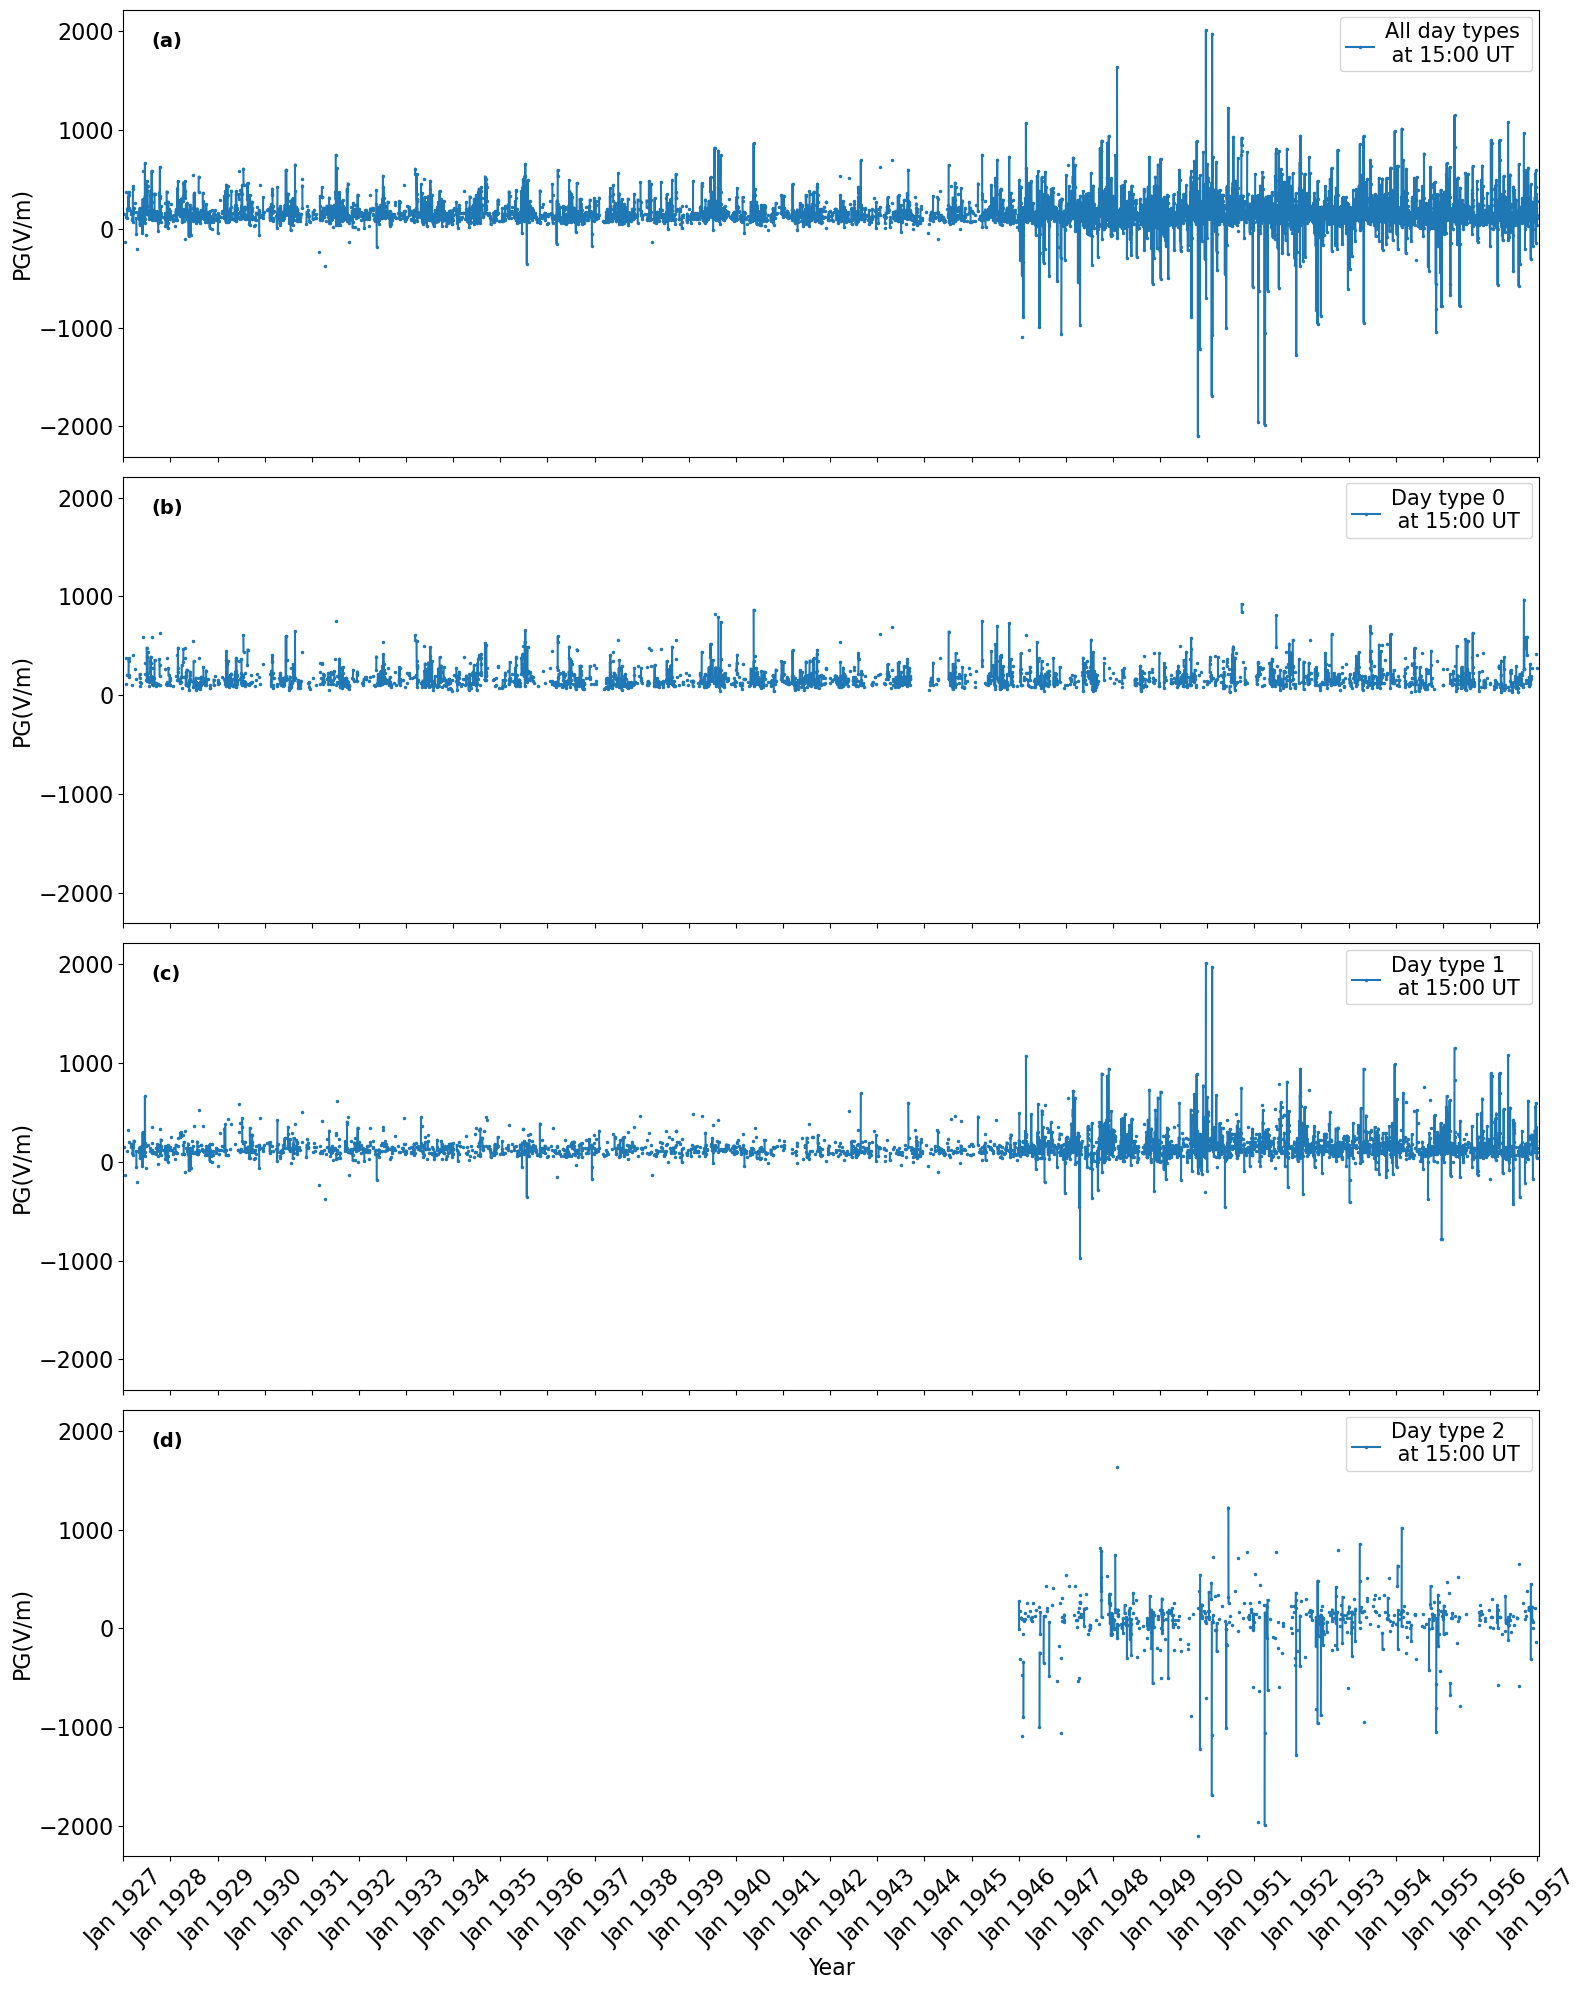

In [10]:
i=15
#dt=1

fig, axes = plt.subplots(4, 1,  figsize=(16, 20), sharex=True, sharey=True)#figsize=(18, 10), sharex=True, sharey=True) 
axes = axes.flatten() 

for dt in range(4):#[0,1,2,5]:
    ax = axes[dt]
    daytype_df =selected_df_temp[dt].sort_values('date')

    tmp = daytype_df[['date', str(i)]].copy()

    gap = tmp['date'].diff().dt.days
    break_idx = tmp.index[gap > 1]

    rows = []
    for idx, row in tmp.iterrows():
        if idx in break_idx:
            rows.append([pd.NaT, np.nan])  # break line
        rows.append([row['date'], row[str(i)]])

    plot_df = pd.DataFrame(rows, columns=['date', str(i)])
    plot_df['date'] = pd.to_datetime(plot_df['date'], errors='coerce')
    plot_df[str(i)] = pd.to_numeric(plot_df[str(i)], errors='coerce')
   
    if dt == 0:
        ax.plot(plot_df['date'],
             plot_df[str(i)],
             linestyle='-',
             marker='.',
             markersize=3,
             label=f'All day types \n at {i}:00 UT '
           )

    elif dt == 1 or dt == 2 :
        ax.tick_params(labelbottom=False)
        ax.plot(plot_df['date'],
             plot_df[str(i)],
             linestyle='-',
             marker='.',
             markersize=3,
             label=f'Day type {dt-1} \n at {i}:00 UT '
           )
    else:
        ax.tick_params(labelbottom=False)
        ax.plot(plot_df['date'],
             plot_df[str(i)],
             linestyle='-',
             marker='.',
             markersize=3,
             label=f'Day type {dt-1} \n at {i}:00 UT '
           )
        ax.tick_params(labelbottom=True)
        ax.set_xlabel('Year', fontsize=16)

   # ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.set_xlim(pd.Timestamp('1927-01-01'),
                pd.Timestamp('1957-01-15'))
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    
    ax.set_ylabel('PG(V/m)', fontsize=16)
    #plt.title('Selected hour from 1927-1956')
    ax.legend()
    
for ax in axes:
    leg = ax.get_legend()
    if leg:
        for text in leg.get_texts():
            text.set_fontsize(15)
            
labels = ['(a)', '(b)', '(c)', '(d)']

for ax, label in zip(axes, labels):
    ax.text(
        0.02, 0.95,
        label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )
plt.xticks(rotation=45)

#plt.ylim(-3000, 3000)
plt.tight_layout()
plt.savefig(fig_out+ 'Figure9.png', dpi=300)
plt.show()

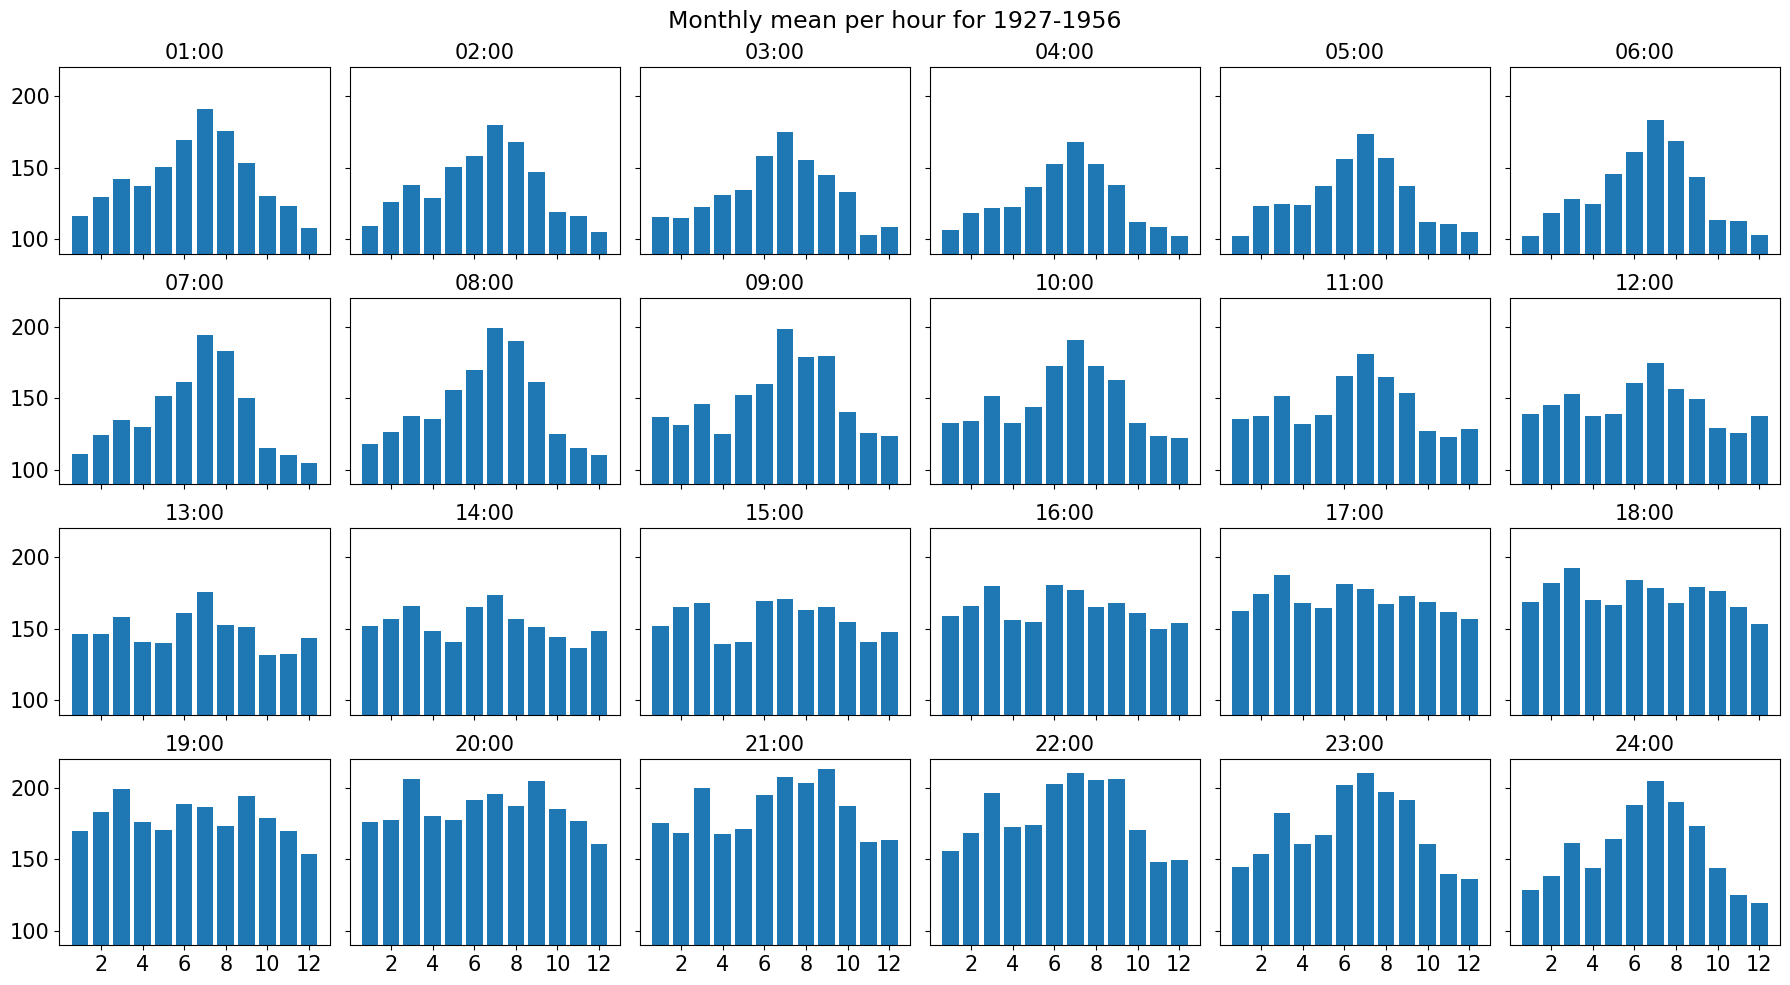

In [7]:
def plot_hourly_hist(df, title, filename): 
    hour_cols = [str(i) 
    for i in range(1, 25)] 
    valid = df_main.groupby('MM')[hour_cols].mean() 
    valid = valid.apply(pd.to_numeric, errors='coerce') 
    fig, axes = plt.subplots(4, 6,  figsize=(18, 10), sharex=True, sharey=True)#figsize=(18, 10), sharex=True, sharey=True) 
    axes = axes.flatten() 
    for i, col in enumerate(hour_cols): 
       
        x = range(1,13)
        y=valid[col].values

        axes[i].bar(x,y) #width=0.8
    
        
        axes[i].set_title(f'{int(col):02d}:00', fontsize=15) 
        axes[i].tick_params(labelsize=15) 
        axes[i].xaxis.set_major_locator(MultipleLocator(2))
        axes[i].set_ylim(90, 220)


    fig.suptitle(title, fontsize=17)
    plt.tight_layout()
    plt.savefig(fig_out + filename, dpi=300)
    plt.show()
    plt.close(fig)



plot_hourly_hist(df_main,  'Monthly mean per hour for 1927-1956', 'monthly_mean_by_hours.png')


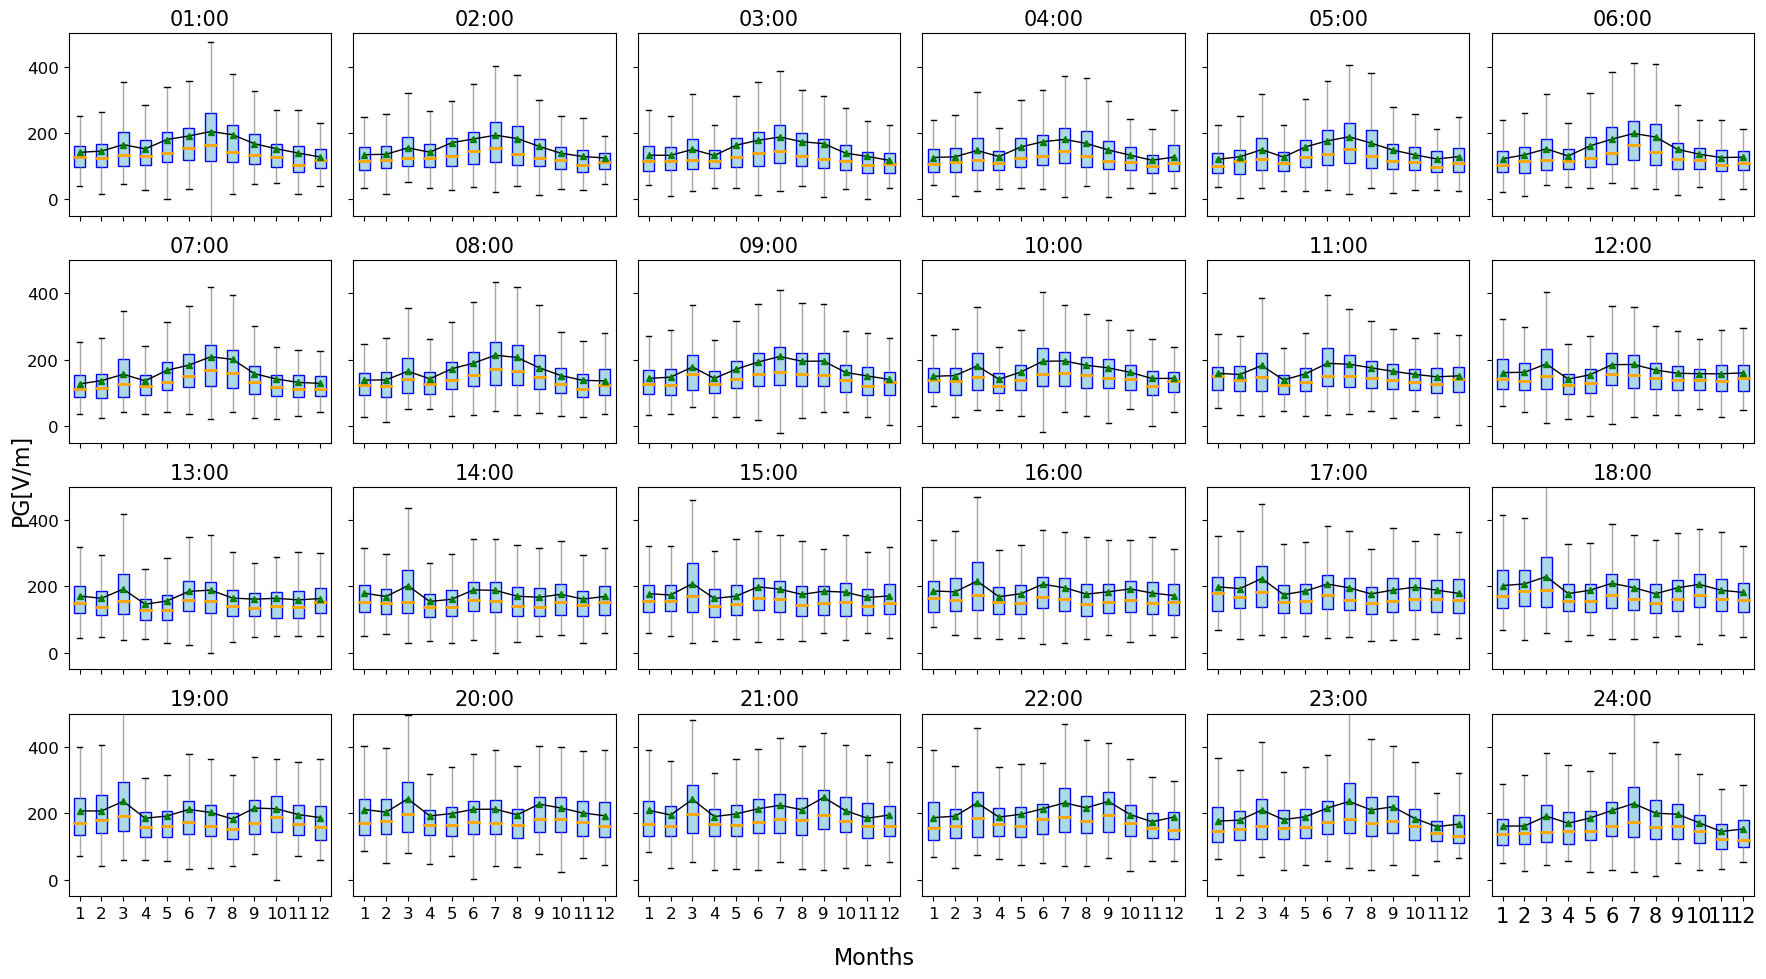

In [14]:
def plot_hourly_boxplot(df, title, filename): 
    hour_cols = [str(i) for i in range(1, 25)] 
    
    fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True, sharey=True)
    axes = axes.flatten() 
    
    for i, col in enumerate(hour_cols): 
        ax = axes[i]

        groups = [
            pd.to_numeric(df_0[df_0['MM'] == m][col], errors='coerce').dropna()
            for m in range(1, 13)
        ]
        means = [g.mean() for g in groups]
        ax.boxplot(
            groups,
                patch_artist=True,
                boxprops=dict(
                facecolor='lightblue',
                color='blue'
                ),
            whiskerprops=dict(
            color='gray',
            linewidth=1,
            alpha=0.7
            ),
            showfliers=False,
            showmeans=True,
            meanline=False,
            meanprops=dict(
                marker='^',
                markerfacecolor='green',
                markeredgecolor='green',
                markersize=4
            ),
            medianprops=dict(
                color='orange',
                linewidth=2
            )
        )
        ax.plot(
        range(1, len(means)+1),
        means,
        color='black',
        linewidth=1
        )
        ax.set_title(f'{int(col):02d}:00', fontsize=15)
        ax.tick_params(labelsize=12)
        ax.set_ylim(-50, 500)
        ax.set_xticks(range(1, 13))
       # ax.set_xlabel('Months',  fontsize=15)
       # ax.set_ylabel(' PG[V/m]',  fontsize=15)
        ax.set_xticklabels(range(1, 13))

        #ax.xaxis.set_major_locator(MultipleLocator(2))


    fig.suptitle(title, fontsize=17)
    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15, rotation=90)
    fig.supxlabel('Months', fontsize=16)
    fig.supylabel('PG[V/m]', fontsize=16)
    #plt.xlabel('Year',  fontsize=16)

    plt.tight_layout()
    plt.savefig(fig_out + filename, dpi=300)
    plt.show()
    plt.close(fig)
    
plot_hourly_boxplot(df_1,  '', 'Figure12.png')#df_main


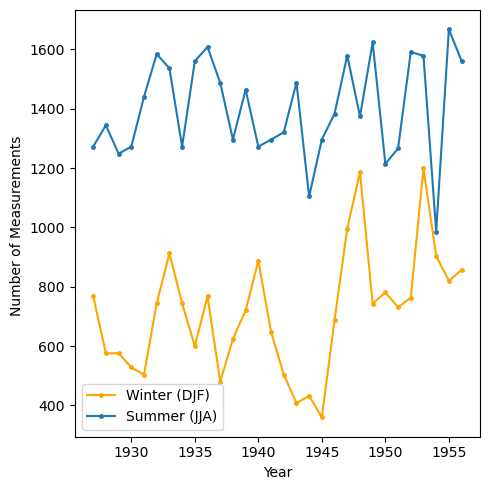

In [15]:
df_sum = pd.read_csv("summary_measurements.txt", sep = "\t")
#print(df_sum['year'])


plt.figure(figsize=(5,5))
x = df_sum['year']

#plt.title(f'Measurments Winter (DJF) vs Summer(JJA)')


ax = plt.gca()

# x-axis every 1 hour
#ax.xaxis.set_major_locator(MultipleLocator(4))

plt.plot(x, df_sum['winter'], 
             linestyle='-',
             marker='.',
             markersize=5,
             color='orange', 
             label= "Winter (DJF)")#f'{dt[i]}')
                
plt.plot(x, df_sum['summer'], linestyle='-',
             marker='.',
             markersize=5, 
             label= "Summer (JJA)")
#plt.xticks(range(1, 25))
plt.xlabel('Year')
plt.ylabel('Number of Measurements ')
plt.legend()
plt.tight_layout()
plt.savefig(fig_out+ 'Figure4B.png', dpi=300)

plt.show()